In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from helper_functions.feature_transformer import *
from helper_functions.visualizations import *
from helper_functions.imputer import CustomIterativeImputer

data = pd.read_csv("../../preliminar_phase_submision/training_data/SyntheticData_Training.csv")
dictionary = pd.read_csv("tmp_datasets/DataDictionary.csv")
target = "inhospital_mortality"

# multi_imputer = CustomIterativeImputer()
X_ = data.drop(columns=['inhospital_mortality', 'studyid_adm', 'lengthadm'],
               errors='ignore')
y_ = data["inhospital_mortality"]

In [ ]:
# flag - if there is no secondary latato reading, 
# low oxygen + low BCS + anemia flag 


['admitabx_adm___1',
 'admitabx_adm___10',
 'admitabx_adm___11',
 'admitabx_adm___12',
 'admitabx_adm___13',
 'admitabx_adm___14',
 'admitabx_adm___15',
 'admitabx_adm___16',
 'admitabx_adm___17',
 'admitabx_adm___18',
 'admitabx_adm___19',
 'admitabx_adm___2',
 'admitabx_adm___20',
 'admitabx_adm___21',
 'admitabx_adm___3',
 'admitabx_adm___4',
 'admitabx_adm___5',
 'admitabx_adm___6',
 'admitabx_adm___7',
 'admitabx_adm___8',
 'admitabx_adm___9',
 'agecalc_adm',
 'alivechildren_adm',
 'badhealthduration_adm',
 'bcgscar_adm',
 'bcseye_adm',
 'bcsmotor_adm',
 'bcsverbal_adm',
 'bednet_adm',
 'birthattend_adm',
 'birthdetail_adm___1',
 'birthdetail_adm___2',
 'birthdetail_adm___3',
 'birthdetail_adm___4',
 'birthdetail_adm___5',
 'birthdetail_adm___6',
 'caprefill_adm',
 'caregiver_adm_new',
 'caregiverage_adm',
 'caregivermarried_adm',
 'comorbidity_adm___1',
 'comorbidity_adm___10',
 'comorbidity_adm___11',
 'comorbidity_adm___12',
 'comorbidity_adm___2',
 'comorbidity_adm___3',
 'com

In [ ]:
import pandas as pd
import numpy as np

class FeatureEngineer:
    def __init__(self):
        """
        Initializes the Feature Engineer with predefined constants, including the feature keys
        and the file paths of the CDC and WHO Growth Charts for BMI and WFL z-score calculations.
        """
        # Primary feature keys
        self.primary_features_keys = [
            'agecalc_adm', 'height_cm_adm', 'weight_kg_adm', 'sex_adm',
            'caprefill_adm', 'glucose_mmolpl_adm', 'hematocrit_gpdl_adm',
            'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'spo2site1_pc_oxi_adm',
            'spo2site2_pc_oxi_adm', 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm',
            'sysbp_mmhg_adm', 'diasbp_mmhg_adm', 'hr_bpm_adm', 'temp_c_adm',
            'bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm']

        # Target column for the dataset
        self.target_column = 'inhospital_mortality'

        # File paths for BMI and WFL z-score CSVs
        self.wfl_csv_path = "charts/WHO-{gender}-Weight-for-length-Percentiles.csv"
        self.bmi_csv_path = "charts/bmiagerev.csv"

        # Loading the WFL percentiles data for z-score calculation
        self.wfl_df = pd.concat(
            [pd.read_csv(f"{self.wfl_csv_path.format(gender=gender)}").assign(gender=gender) for gender in ['Boys', 'Girls']],
            ignore_index=True)

    def fit(self, X, y=None):
        """
        Placeholder method for fit.
        
        :param X: The input data (DataFrame)
        :param y: The target values
        """
        pass  # Not used in this case, but can be extended if needed
    
    def transform(self, X, y=None):
        """
        Transforms the dataset by handling missing values, engineering secondary features,
        and preparing the final dataset.

        :param X: The input data (DataFrame)
        :param y: The target values
        :return: Transformed DataFrame with primary and secondary features
        """
        X = X.copy()
        print(X.shape)
        # Step 1: Select only the primary features columns
        X = X[self.primary_features_keys]
        print(X.shape)
        print(X.isna().sum().sum())
        
        # Step 2: Fill missing values in specific columns
        X["lactate2_mmolpl_adm"].fillna(X["lactate_mmolpl_adm"], inplace=True)
        X["spo2site2_pc_oxi_adm"].fillna(X["spo2site1_pc_oxi_adm"], inplace=True)
        X["sqi2_perc_oxi_adm"].fillna(X["sqi1_perc_oxi_adm"], inplace=True)
        
        # Step 3: Drop rows with missing values
        X[target] = y
        X = X.dropna()
        y = X[target]
        print(X.shape)
        print(X.isna().sum().sum())
        
        # Step 4: Engineer the secondary features
        ## A higher shock index indicates worse perfusion and is associated with shock.
        X['shock_index'] = X['hr_bpm_adm'] / X['sysbp_mmhg_adm']
        # MAP < 65 mmHg is a sign of hypotension and poor perfusion.
        X['map'] = X['diasbp_mmhg_adm'] + X['sysbp_mmhg_adm'] / 3 - X['diasbp_mmhg_adm']
        X['hypotension_flag'] = np.where(X['map'] < 65, False, True)
        # lactate clearance < 10%: Associated with poor outcomes, including higher mortality and organ failure. 
        # a negative value indicates rising lactate (worsening tissue hypoxia)
        X['lactate_clearance'] = 100 * (X['lactate_mmolpl_adm'] - X['lactate2_mmolpl_adm']) / X['lactate_mmolpl_adm']
        X['hypoxia_flag'] = np.where(X['lactate_clearance'] < 10, False, True)
        X['extreme_hypoxia_flag'] = np.where(X['lactate_clearance'] < 0, False, True)

        # Step 5: Calculate the Blantyre_coma_scale
        # The minimum score is 0 which indicates poor results while the maximum is 5 indicating good results. 
        # All scores under 5 are considered abnormal
        X['bcseye_numeric'] = np.where(X['bcseye_adm'] == "Watches or follows", 1, 0)
        X['bcsverbal_numeric'] = np.where(X['bcsverbal_adm'] == 'Cries appropriately with pain, or, if verbal, speaks', 1, 0)
        conditions = [
            X['bcsmotor_adm'] == 'Localizes painful stimulus',
            X['bcsmotor_adm'] == 'Withdraws limb from painful stimulus',
            X['bcsmotor_adm'] == 'No response or inappropriate response']
        values = [2, 1, 0]
        X['bcsmotor_numeric'] = np.select(conditions, values, default=0)
        X['bcs_adm'] = X['bcseye_numeric'] + X['bcsverbal_numeric'] + X['bcsmotor_numeric']
        X['bcs_adm'] = pd.to_numeric(X['bcs_adm'])

        X['bcs_flag'] = np.where(X['bcs_adm'] == 5, False, True)
                
        # Step 6: Calculate and add Z-scores to X
        X['z_score'] = self._calculate_z_score(
            X['sex_adm'], X['agecalc_adm'], X['height_cm_adm'], X['weight_kg_adm']
        )

        # Step 7: Enhance primary features

        # 1 if glucose < 4 mmol/L (hypoglycemia) or > 10 mmol/L (hyperglycemia), 0 otherwise
        X['glycemia_flag'] = np.where((X['glucose_mmolpl_adm'] >= 4) & (X['glucose_mmolpl_adm'] <= 10), False, True)

        # 1 if hematocrit < 30% (anemia), 0 otherwise
        X['anemia_flag'] = np.where(X['hematocrit_gpdl_adm'] >= 30, False, True)
        # 1 if hematocrit < 20% (anemia), 0 otherwise
        X['severe_anemia_flag'] = np.where(X['hematocrit_gpdl_adm'] >= 20, False, True)

        # 1 if lactate ≥ 2.0 mmol/L (hyperlactatemia), 0 otherwise
        X['hyperlactatemia_flag'] = np.where(X['lactate_mmolpl_adm'] < 2, False, True)

        # 1 if lactate ≥ 4.0 mmol/L (lactic acidosis), 0 otherwise
        X['lactic_acidosis_flag'] = np.where(X['lactate_mmolpl_adm'] < 5, False, True)

        # 1 if temperature > 38°C (fever) or < 36°C (hypothermia), 0 otherwise
        X['hypo_hyper_thermia_flag'] = np.where(
            (X['temp_c_adm'] > 36) & (X['temp_c_adm'] < 38), False, True)

        # Select the more reliable SpO2 value based on SQI
        conditions = [
            X['sqi1_perc_oxi_adm'] > X['sqi2_perc_oxi_adm'],
            X['sqi2_perc_oxi_adm'] > X['sqi1_perc_oxi_adm'],
            np.isclose(X['sqi1_perc_oxi_adm'], X['sqi2_perc_oxi_adm'], atol=0.01)  # Adjust tolerance if needed
        ]
        choices = [
            X['spo2site1_pc_oxi_adm'],
            X['spo2site2_pc_oxi_adm'],
            np.minimum(X['spo2site1_pc_oxi_adm'], X['spo2site2_pc_oxi_adm'])
        ]
        X['spo_selected'] = np.select(conditions, choices, default=np.nan)  # Default can be adjusted if needed
        
        # 1 if SpO2: < 95% on room air (hypoxemia), 0 otherwise
        X['hypoxemia_flag'] = np.where(X['spo_selected'] >95, False, True)

        # X['leukocyte_indicator'] = (
        #     X['hypo_hyper_thermia_flag'] + 
        #     X['hypotension_flag'] + 
        #     X['caprefill_adm'].astype('bool') + 
        #     X['hypoxia_flag'] + 
        #     X['extreme_hypoxia_flag'] + 
        #     X['hypoxemia_flag'] + 
        #     X['lactate_elevated_flag'] + 
        #     X['anemia_flag'] + 
        #     (X['hr_bpm_adm'] > 100).astype(int) +  # Tachycardia as a sign of sepsis
        #     (X['temp_c_adm'] > 38).astype(int)  # Fever component
        # )

        
        # Step 7: Return the transformed DataFrame
        return X


    def fit_transform(self, X, y=None):
        """
        Combines fit and transform methods.
        """
        self.fit(X, y)
        return self.transform(X, y)

    def _calculate_bmi_zscore(self, sex_adm, agecalc_adm, height_cm_adm, weight_kg_adm):
        """Vectorized BMI-for-age z-score calculation for children > 24 months."""
        bmi = weight_kg_adm / ((height_cm_adm / 100) ** 2)  # Vectorized BMI calculation

        df = pd.read_csv(self.bmi_csv_path, skiprows=[220])

        # Convert "Male"/"Female" to 1/2 and filter in a vectorized manner
        sex_code = np.where(sex_adm.str.lower() == "male", 1, 2)
        df = df[df["Sex"].isin(sex_code)]
        df = df.sort_values("Agemos")

        # Perform merge_asof in a vectorized way
        age_df = pd.DataFrame({"Agemos": agecalc_adm})
        merged = pd.merge_asof(age_df.sort_values("Agemos"), df, on="Agemos", direction="nearest")

        L, M, S = merged[['L', 'M', 'S']].values.T  # Extract L, M, S as arrays
        z_scores = ((bmi / M) ** L - 1) / (L * S)  # Vectorized z-score calculation

        return z_scores

    def _calculate_wfl_zscore(self, sex_adm, height_cm_adm, weight_kg_adm):
        """Vectorized weight-for-length z-score calculation for children ≤ 24 months."""
        # Filter the DataFrame based on sex_adm
        sex_code = np.where(sex_adm.str.lower() == "male", 'Boys', 'Girls')
        df = self.wfl_df[self.wfl_df["gender"].isin(sex_code)].sort_values("Length")

        # Perform merge_asof in a vectorized way
        length_df = pd.DataFrame({"Length": height_cm_adm})
        merged = pd.merge_asof(length_df.sort_values("Length"), df, on="Length", direction="nearest")

        L, M, S = merged[['L', 'M', 'S']].values.T  # Extract L, M, S as arrays
        z_scores = ((weight_kg_adm / M) ** L - 1) / (L * S)  # Vectorized z-score calculation

        return z_scores

    def _calculate_z_score(self, sex_adm, agecalc_adm, height_cm_adm, weight_kg_adm):
        """Vectorized function to determine and calculate the correct z-score."""
        z_scores = np.where(
            agecalc_adm > 24,
            self._calculate_bmi_zscore(sex_adm, agecalc_adm, height_cm_adm, weight_kg_adm),
            self._calculate_wfl_zscore(sex_adm, height_cm_adm, weight_kg_adm)
        )
        return z_scores


In [6]:
tmp = data.drop(columns=['studyid_adm', 'lengthadm'],
               errors='ignore')

X_ = tmp.drop(columns=target)
y_ = tmp[target]
feature = FeatureEngineer()
X = feature.fit_transform(X_, y_)

(2148, 137)
(2148, 20)
2970
(1403, 21)
0


# Visualizations

Index(['agecalc_adm', 'glucose_mmolpl_adm', 'hematocrit_gpdl_adm',
       'lactate_mmolpl_adm', 'lactate2_mmolpl_adm', 'spo2site1_pc_oxi_adm',
       'spo2site2_pc_oxi_adm', 'sqi1_perc_oxi_adm', 'sqi2_perc_oxi_adm',
       'sysbp_mmhg_adm', 'diasbp_mmhg_adm', 'hr_bpm_adm', 'temp_c_adm',
       'shock_index', 'map', 'lactate_clearance', 'bcseye_numeric',
       'bcsverbal_numeric', 'bcsmotor_numeric', 'bcs_adm', 'z_score',
       'spo_selected'],
      dtype='object')
Index(['sex_adm', 'caprefill_adm', 'hypotension_flag', 'hypoxia_flag',
       'extreme_hypoxia_flag', 'bcs_flag', 'glycemia_flag', 'anemia_flag',
       'severe_anemia_flag', 'hyperlactatemia_flag', 'lactic_acidosis_flag',
       'hypo_hyper_thermia_flag', 'hypoxemia_flag'],
      dtype='object')


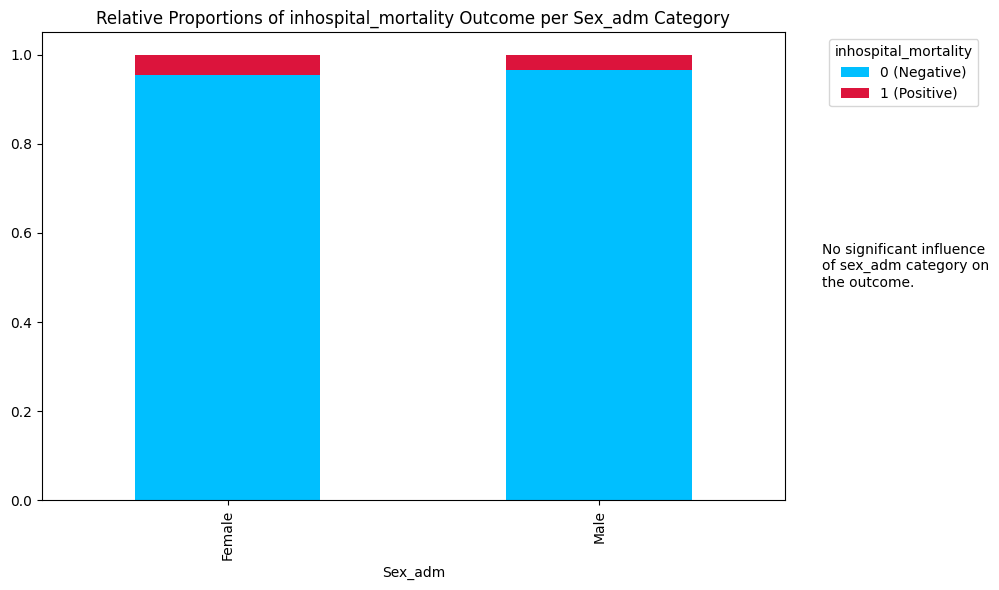

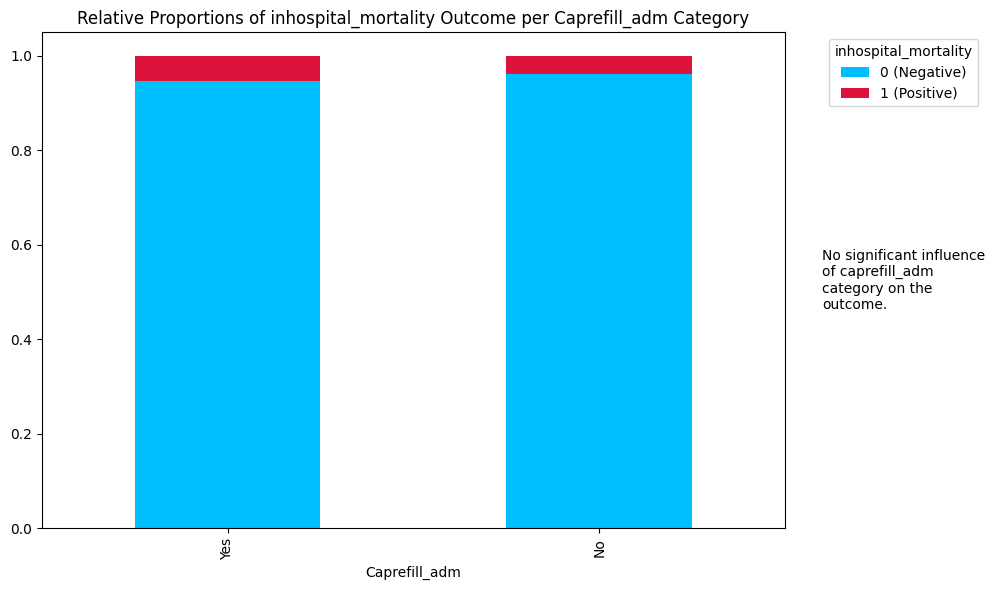

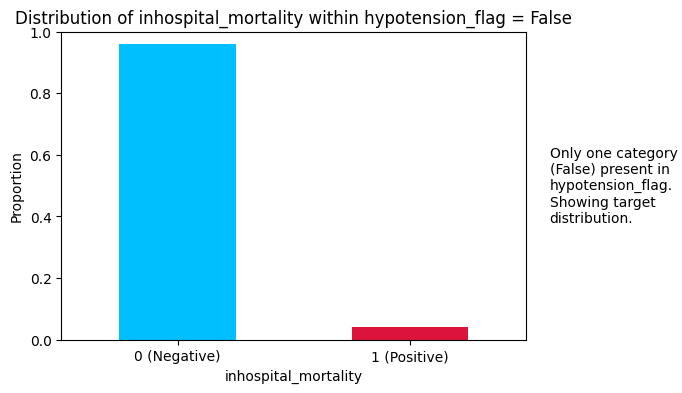

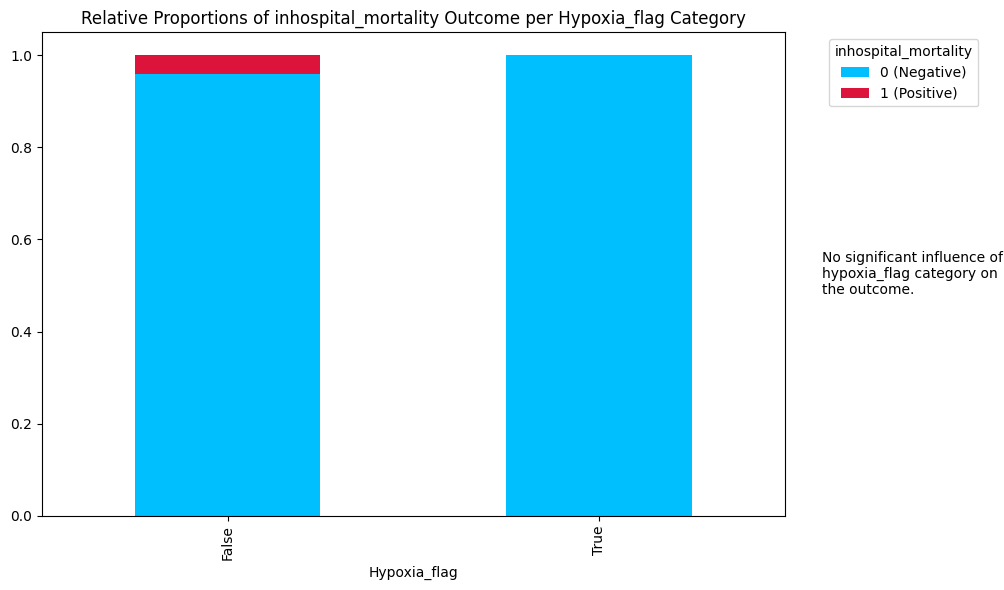

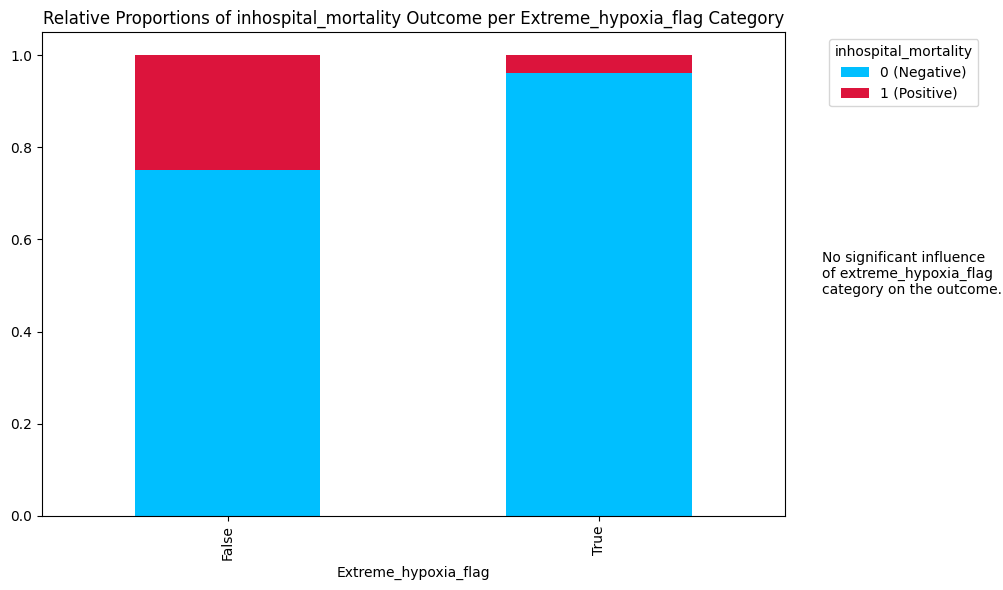

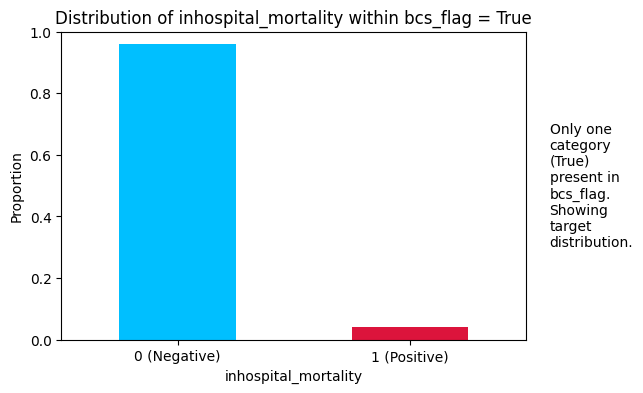

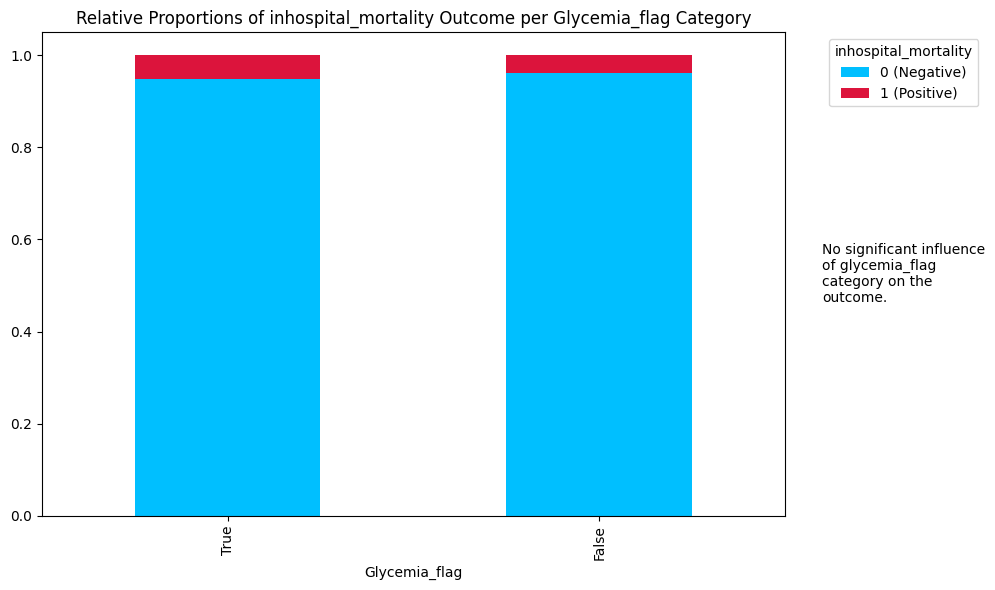

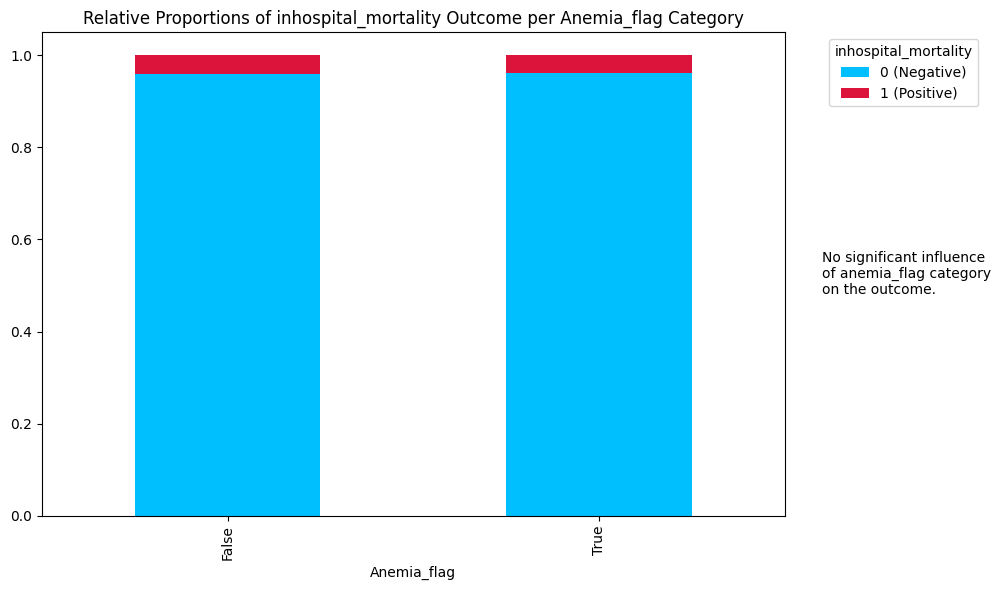

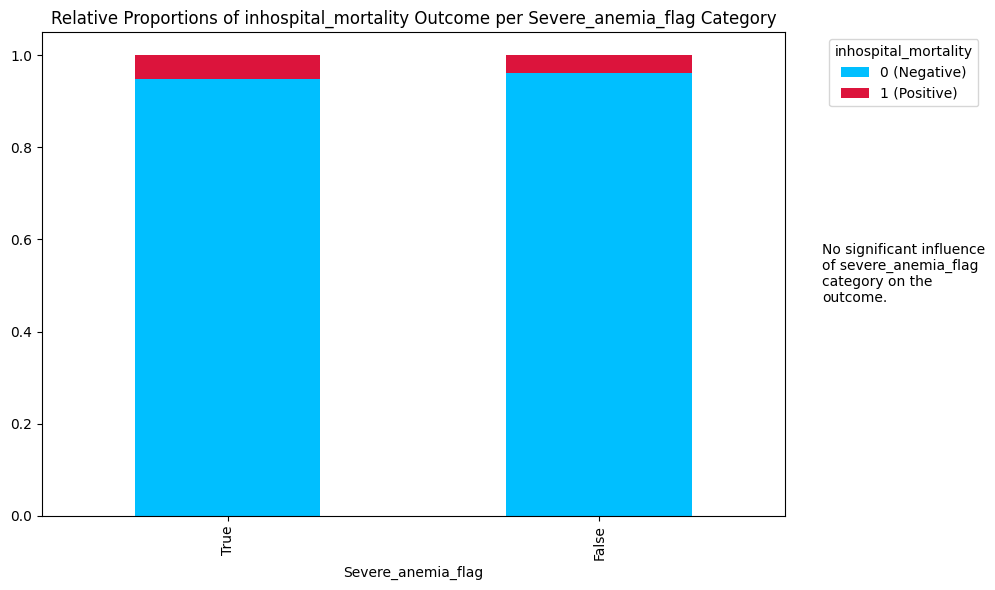

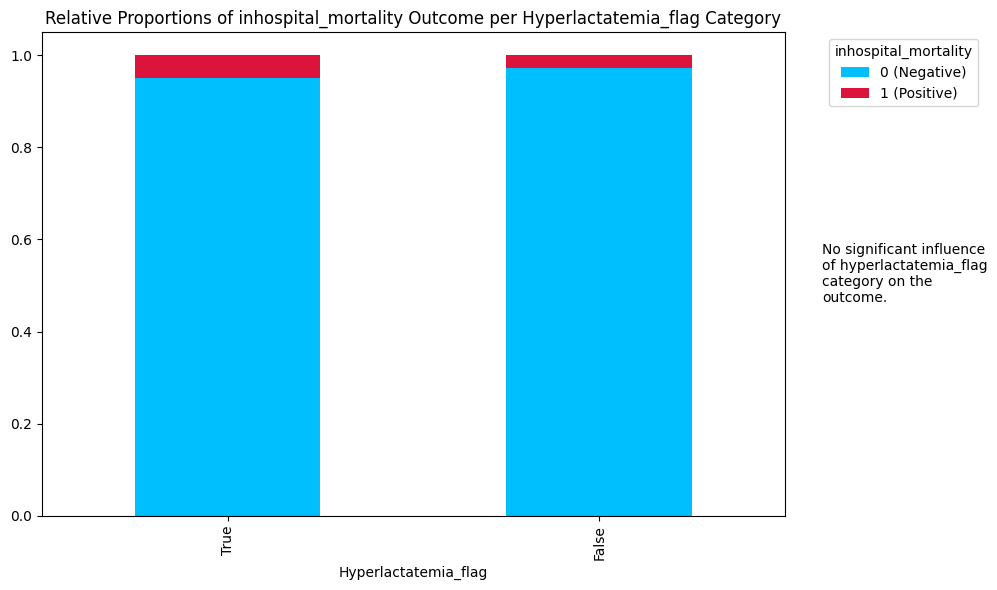

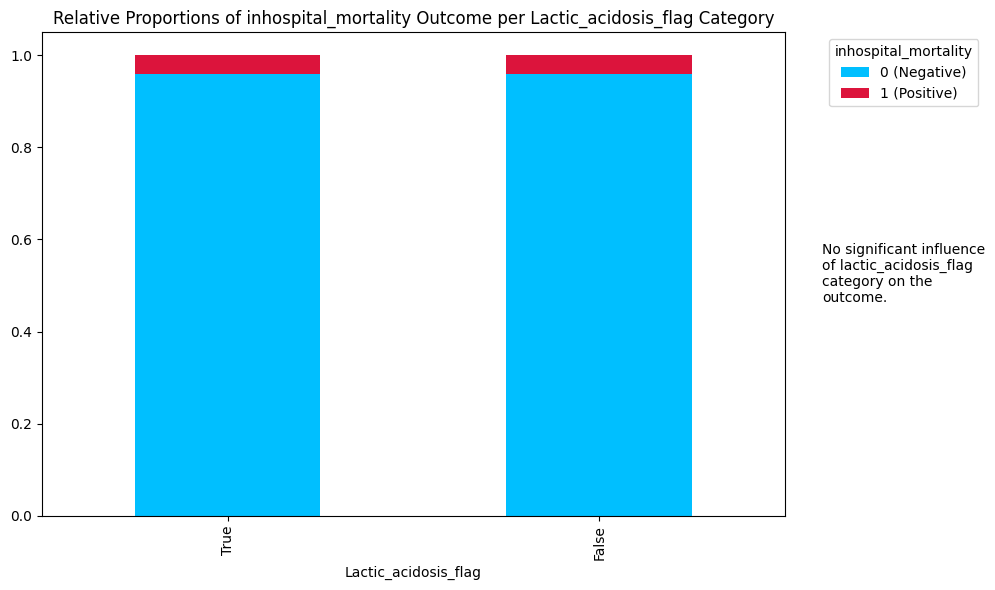

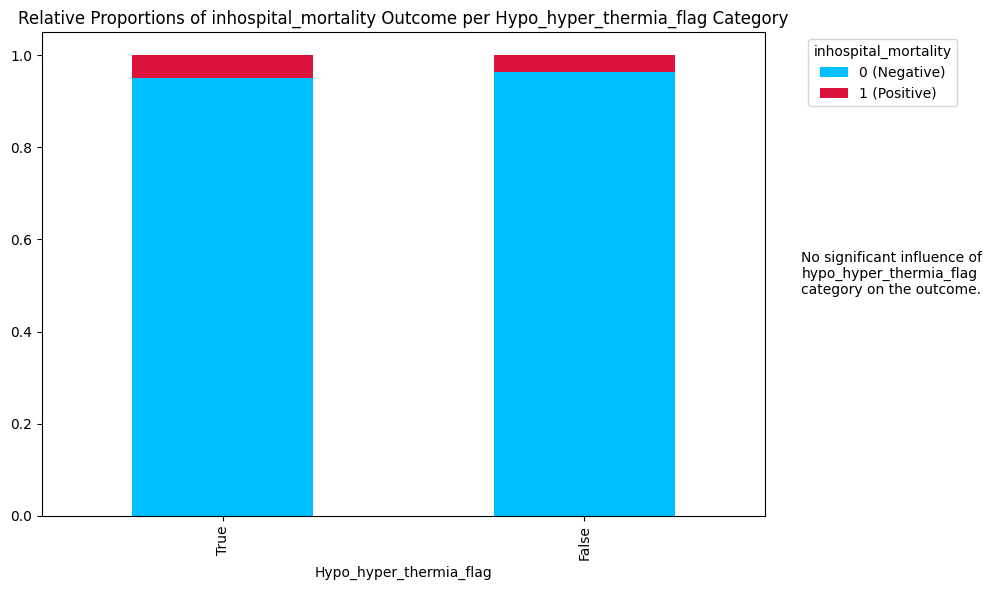

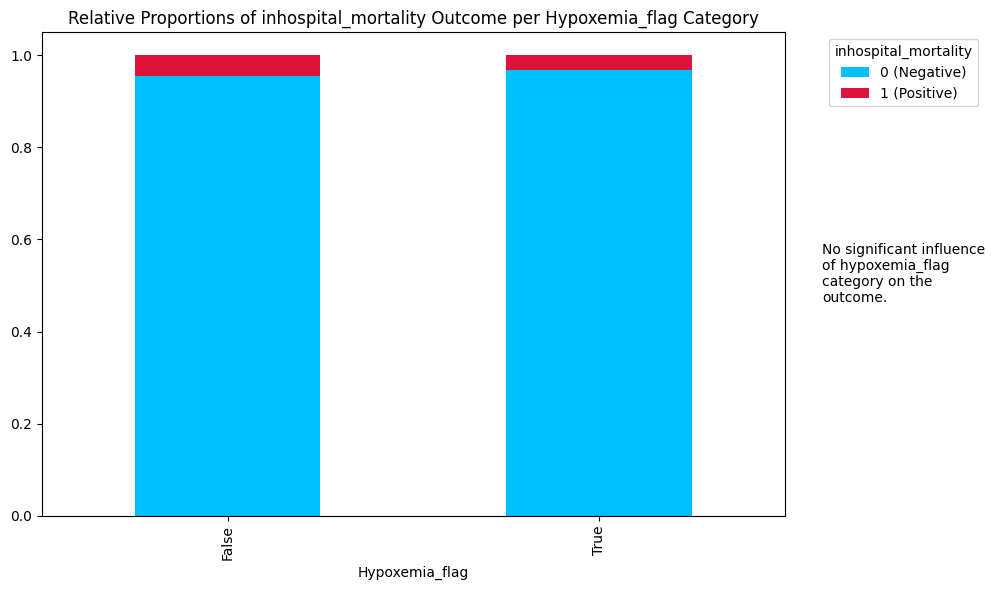

In [7]:
df = X.copy()
df.drop(columns=['height_cm_adm', 'weight_kg_adm'], inplace=True)
df.drop(columns=['bcseye_adm', 'bcsmotor_adm', 'bcsverbal_adm',], inplace=True)

X = df.drop(columns=[target])
numerical_cols = X.select_dtypes(include='number').columns
categorical_cols = X.select_dtypes(exclude='number').columns
print(numerical_cols)
print(categorical_cols)
for col in categorical_cols:
    try:
        categorical_analysis(col, df, target, color=['#00BFFF', '#DC143C'])
    except Exception as e:
        print(col)
        print(e)

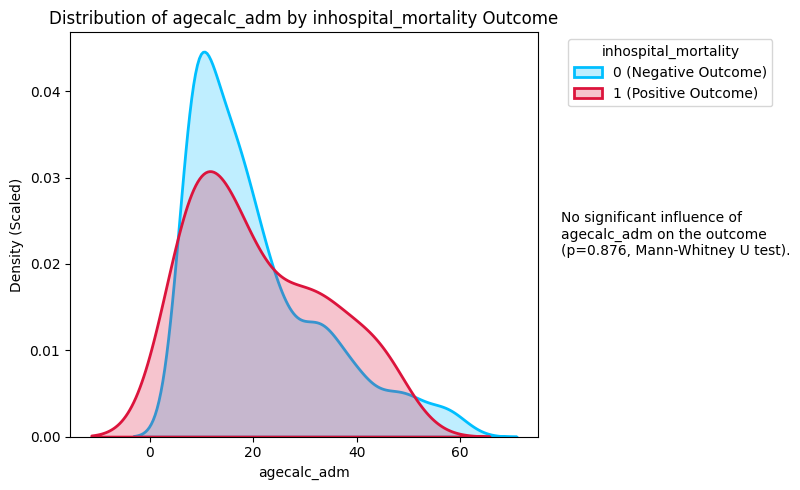

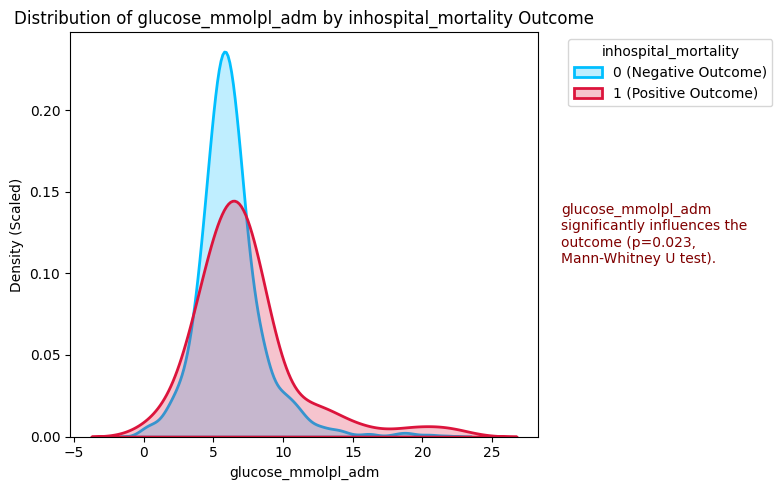

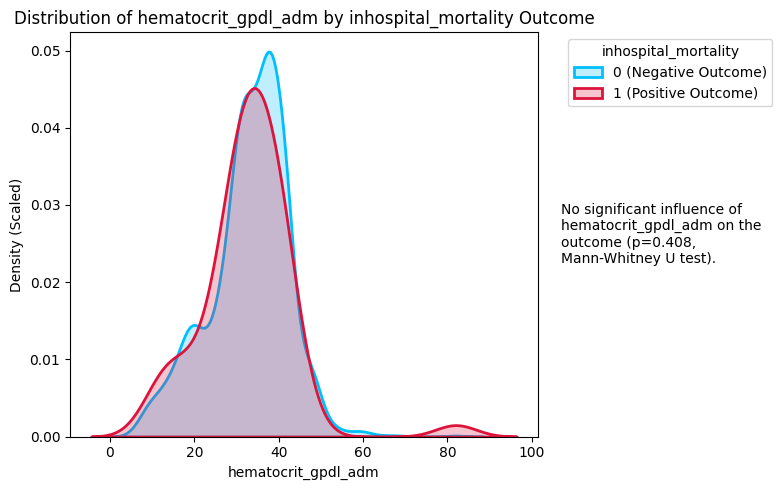

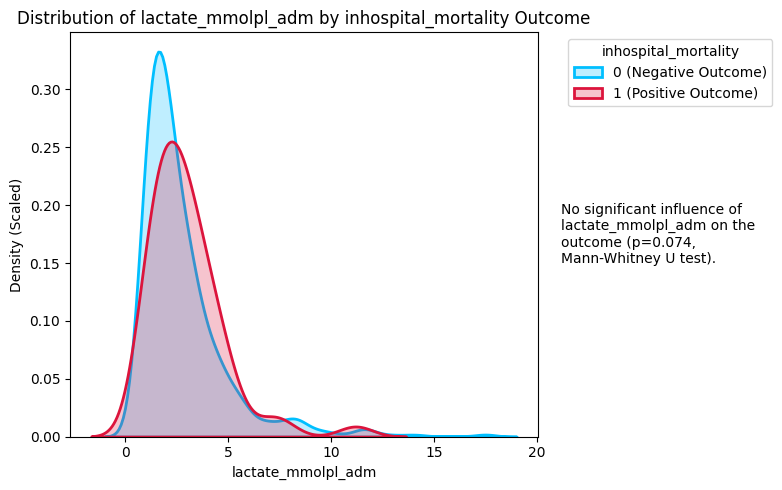

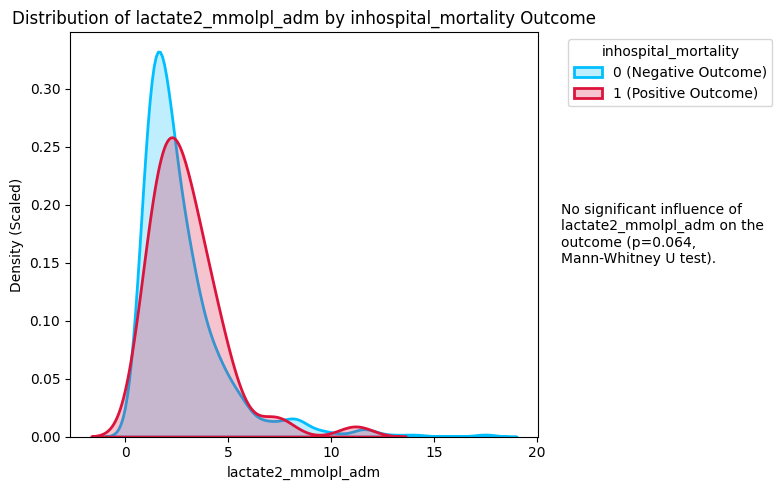

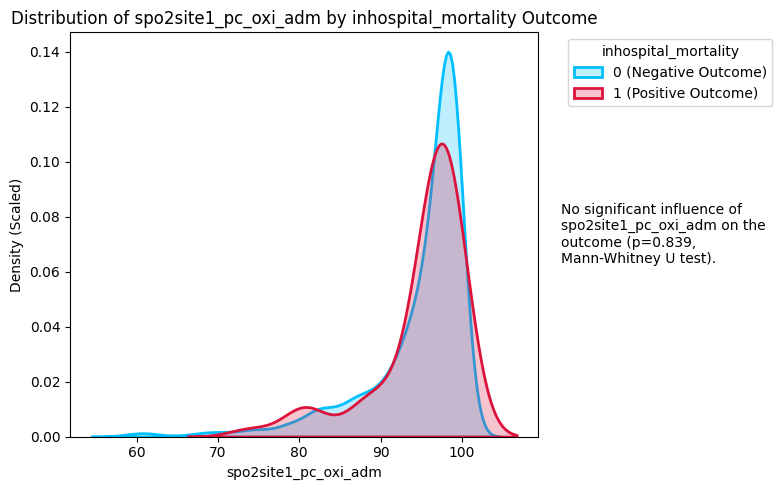

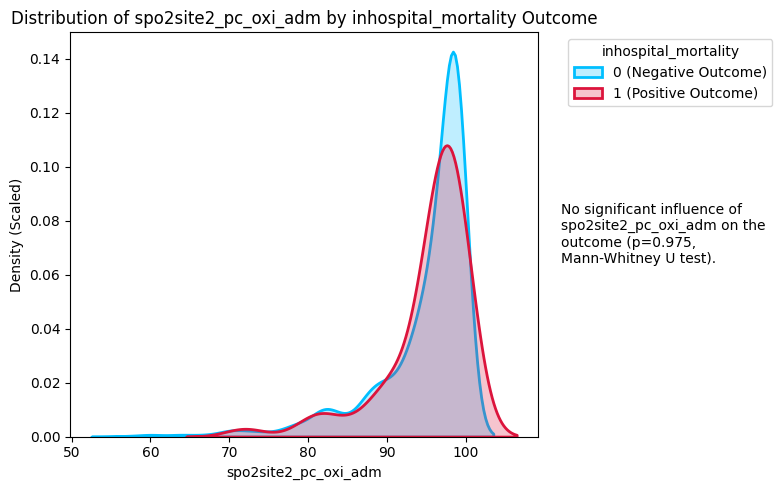

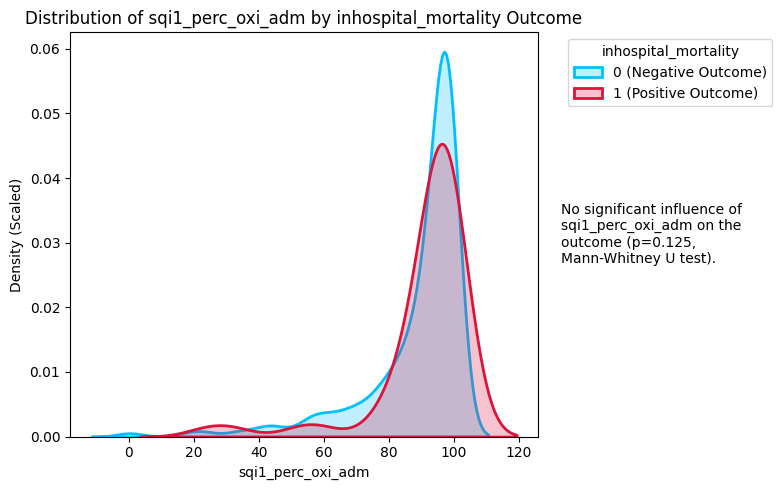

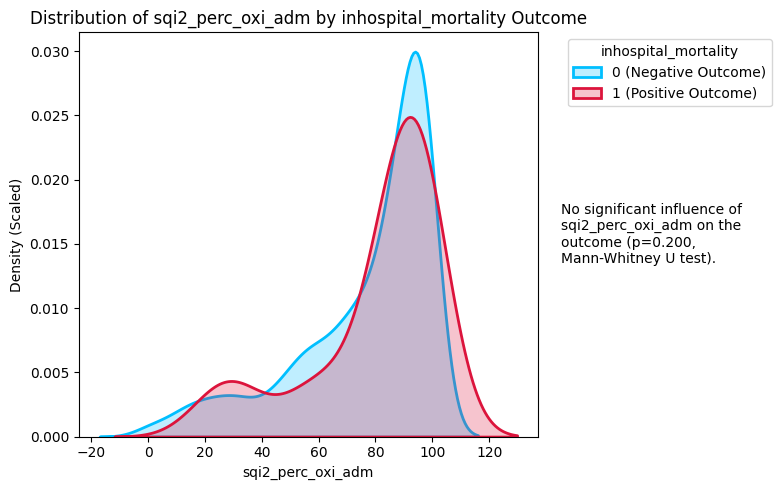

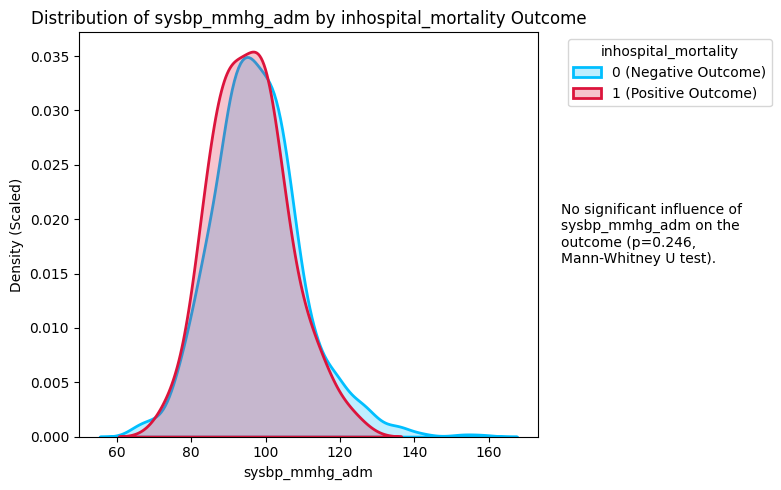

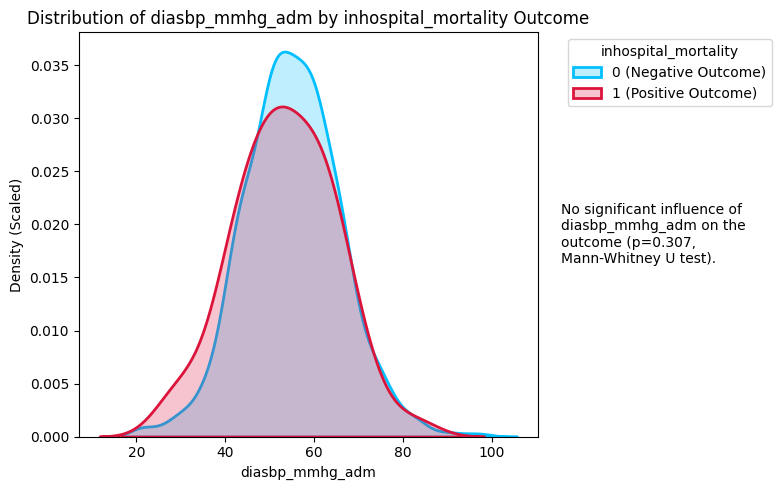

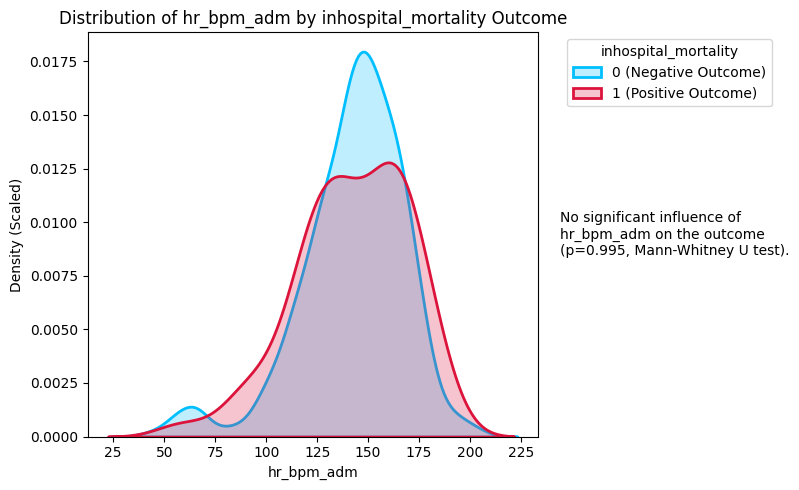

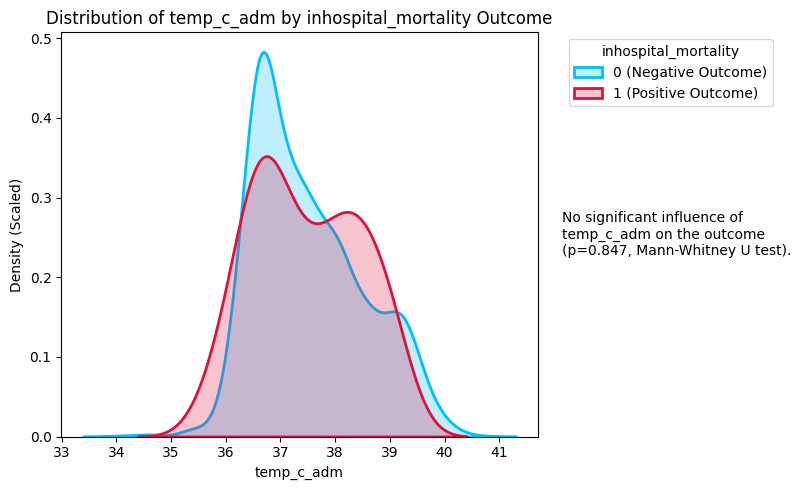

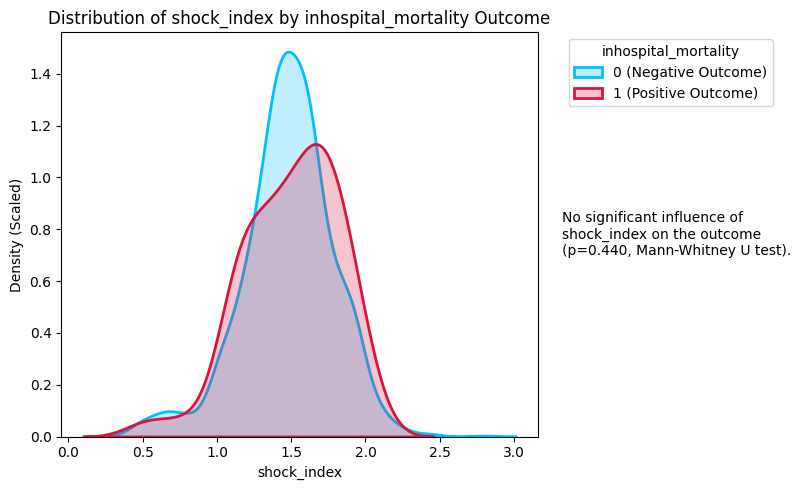

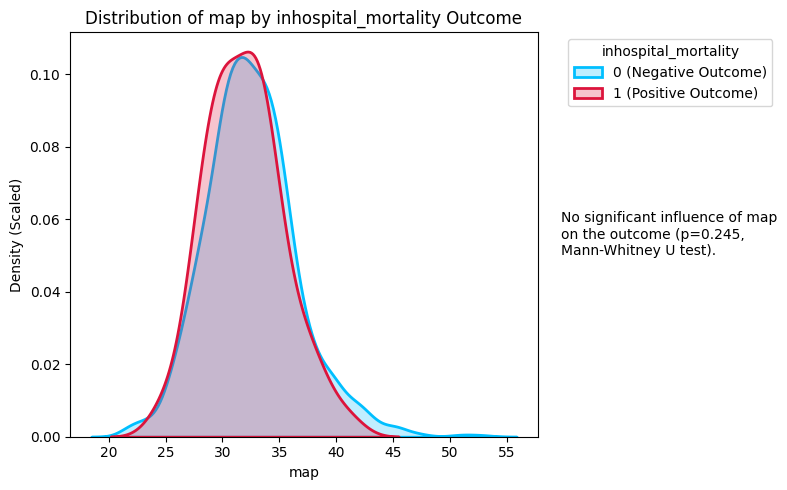

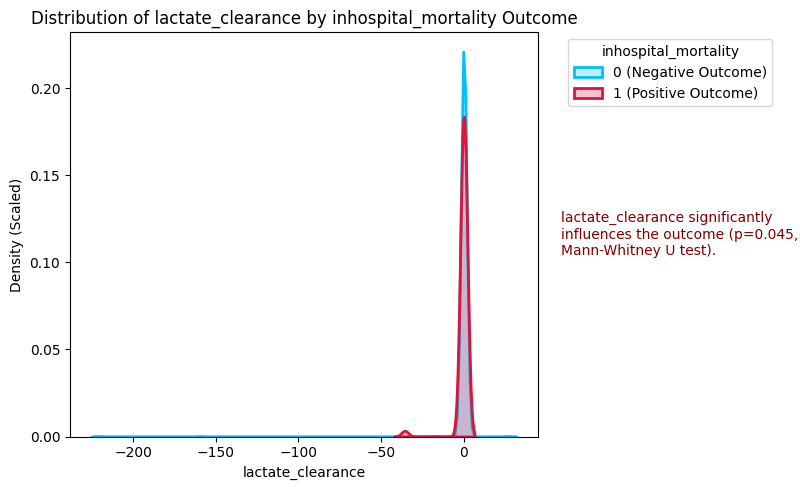

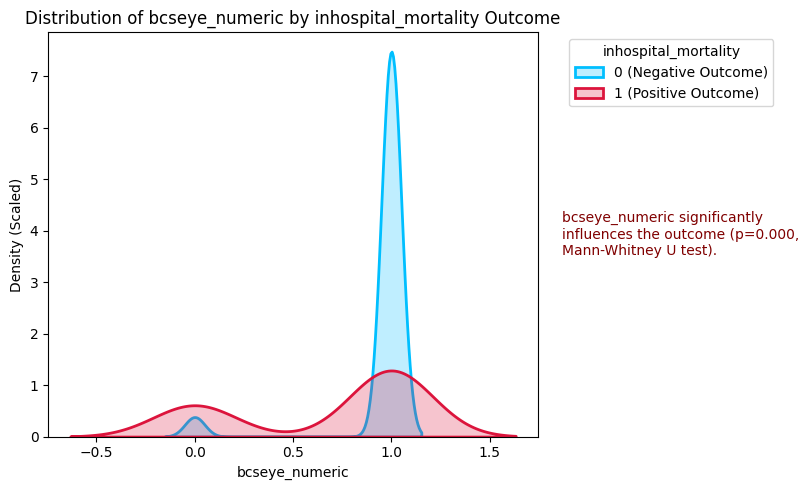

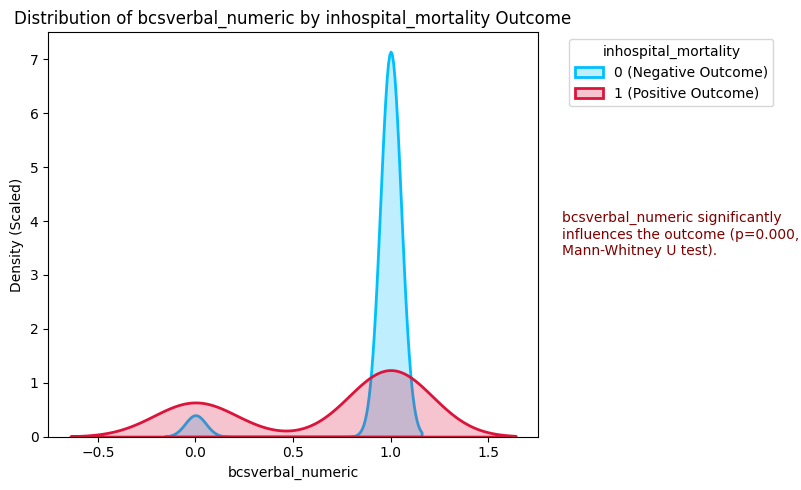

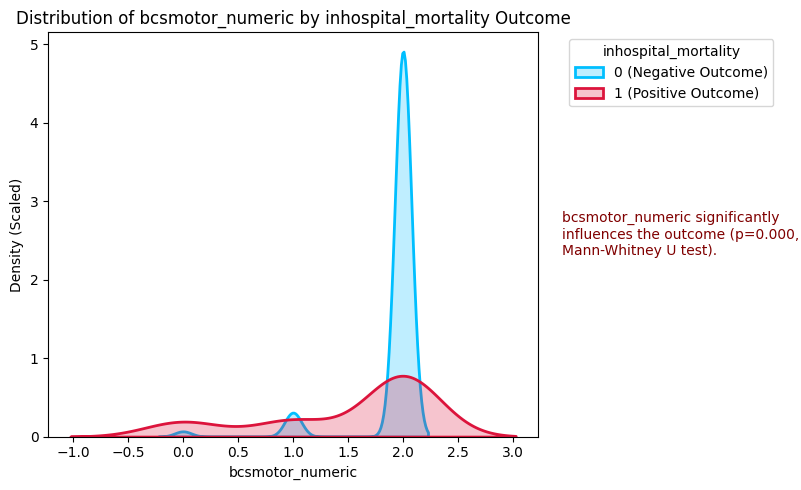

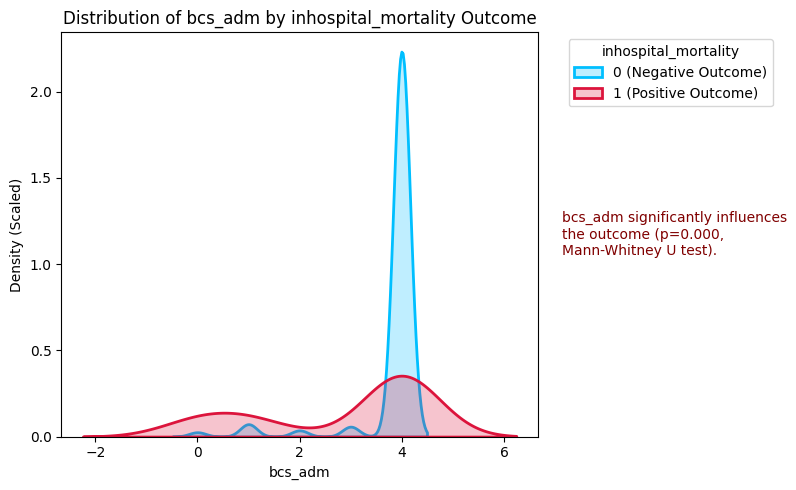

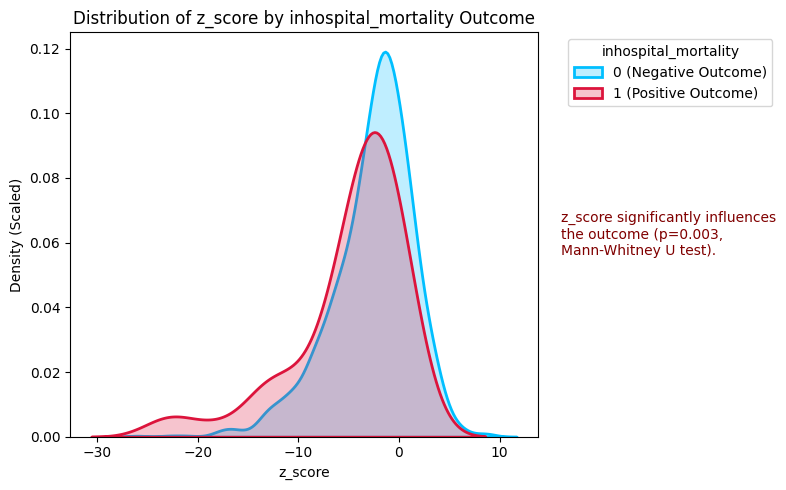

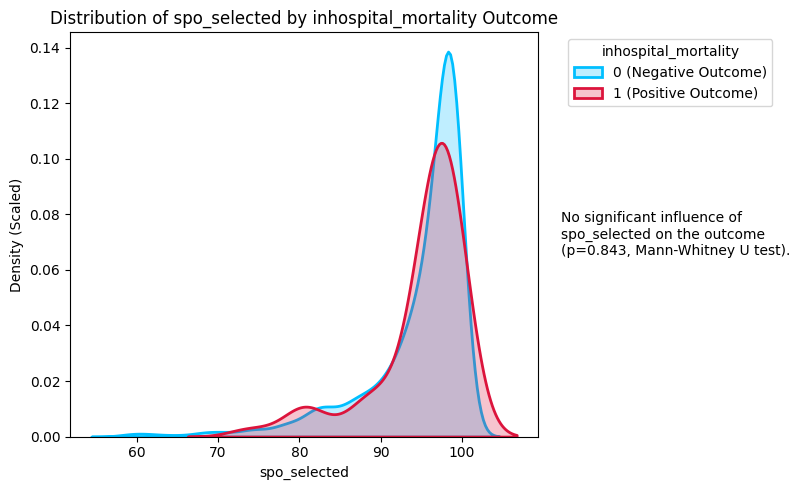

In [8]:
for col in numerical_cols:  
    numerical_analysis(col, df, target)

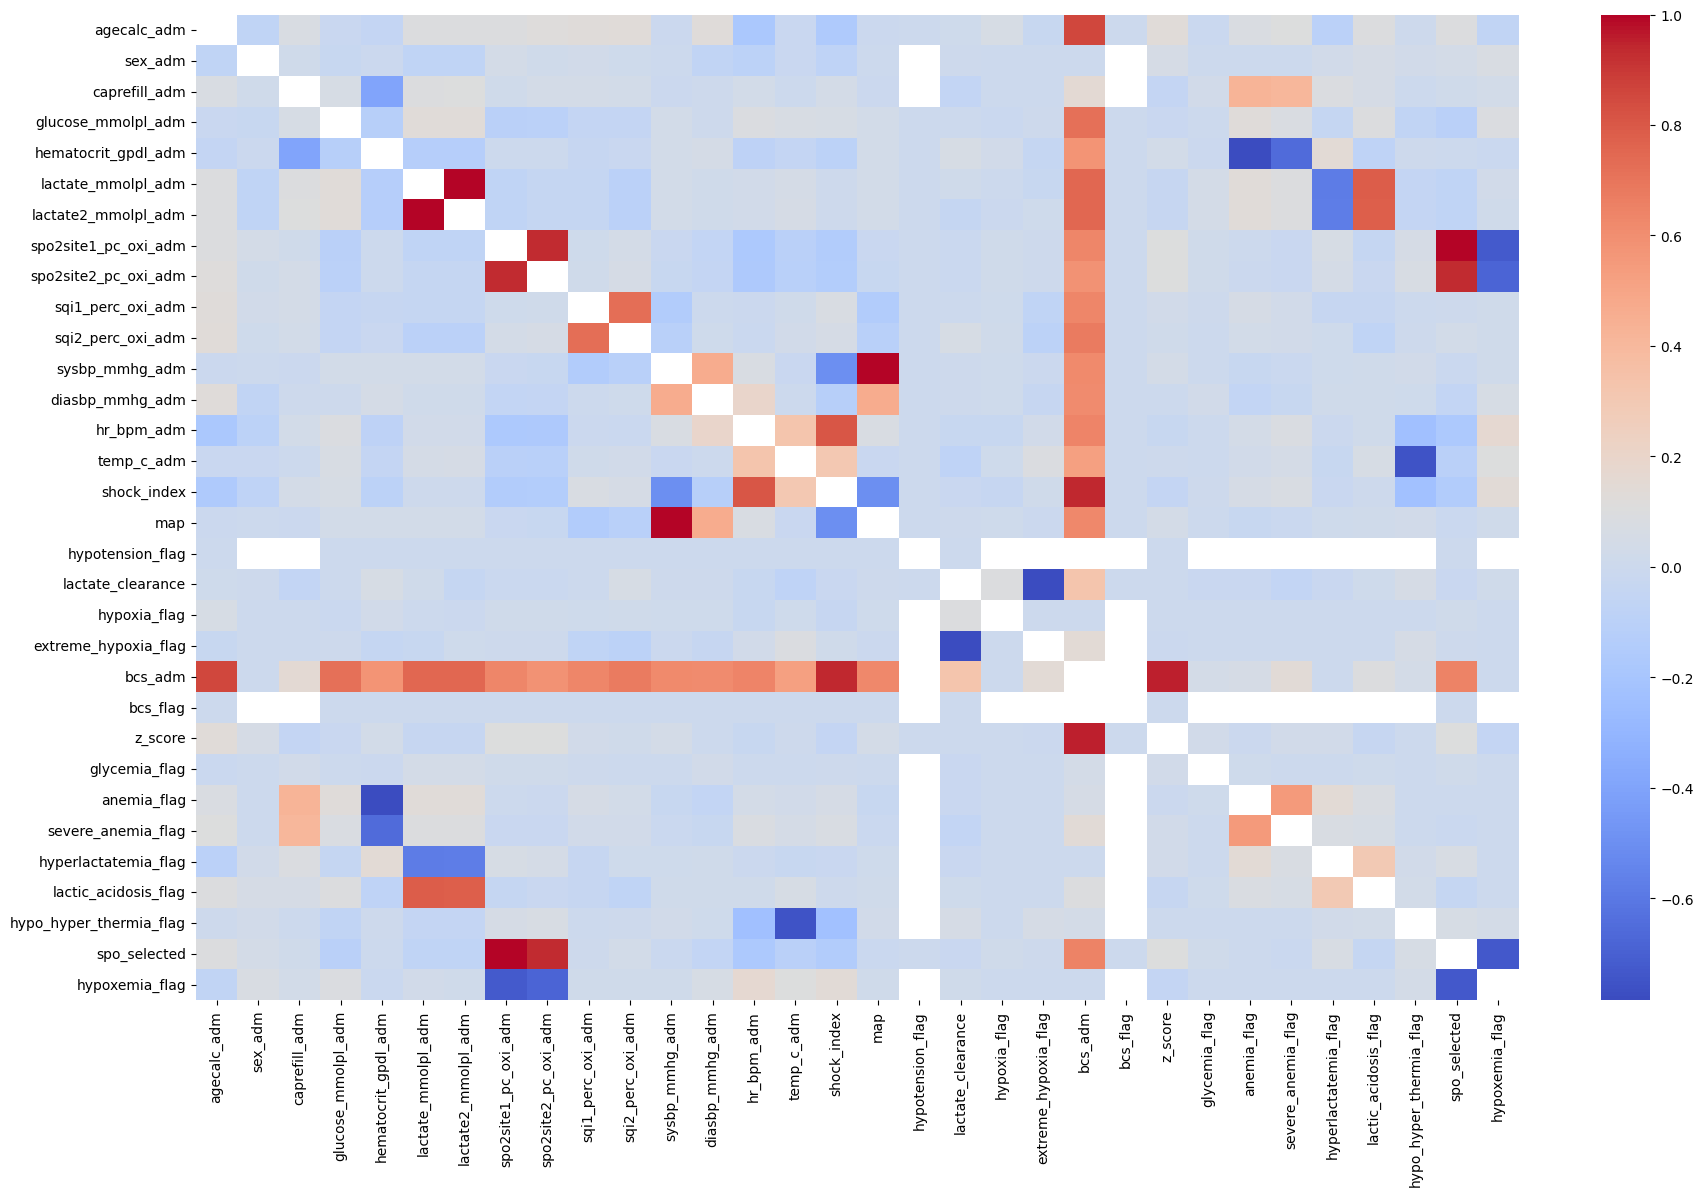

In [ ]:
corr_matrix = heatmap_all_correlations(X)

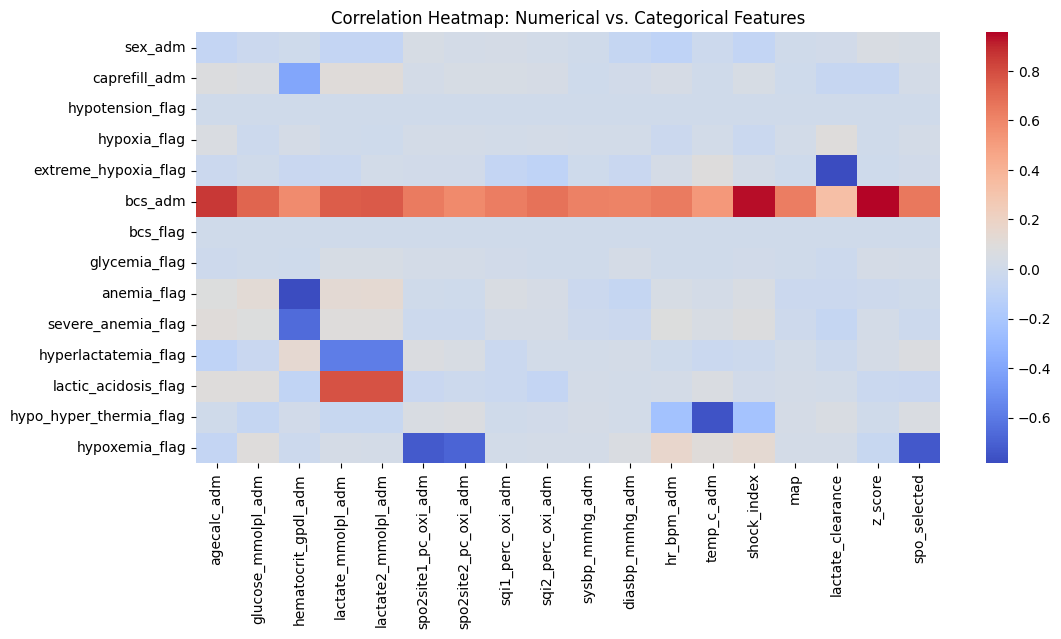

In [ ]:
heatmap_categorical_numerical_cols(X)

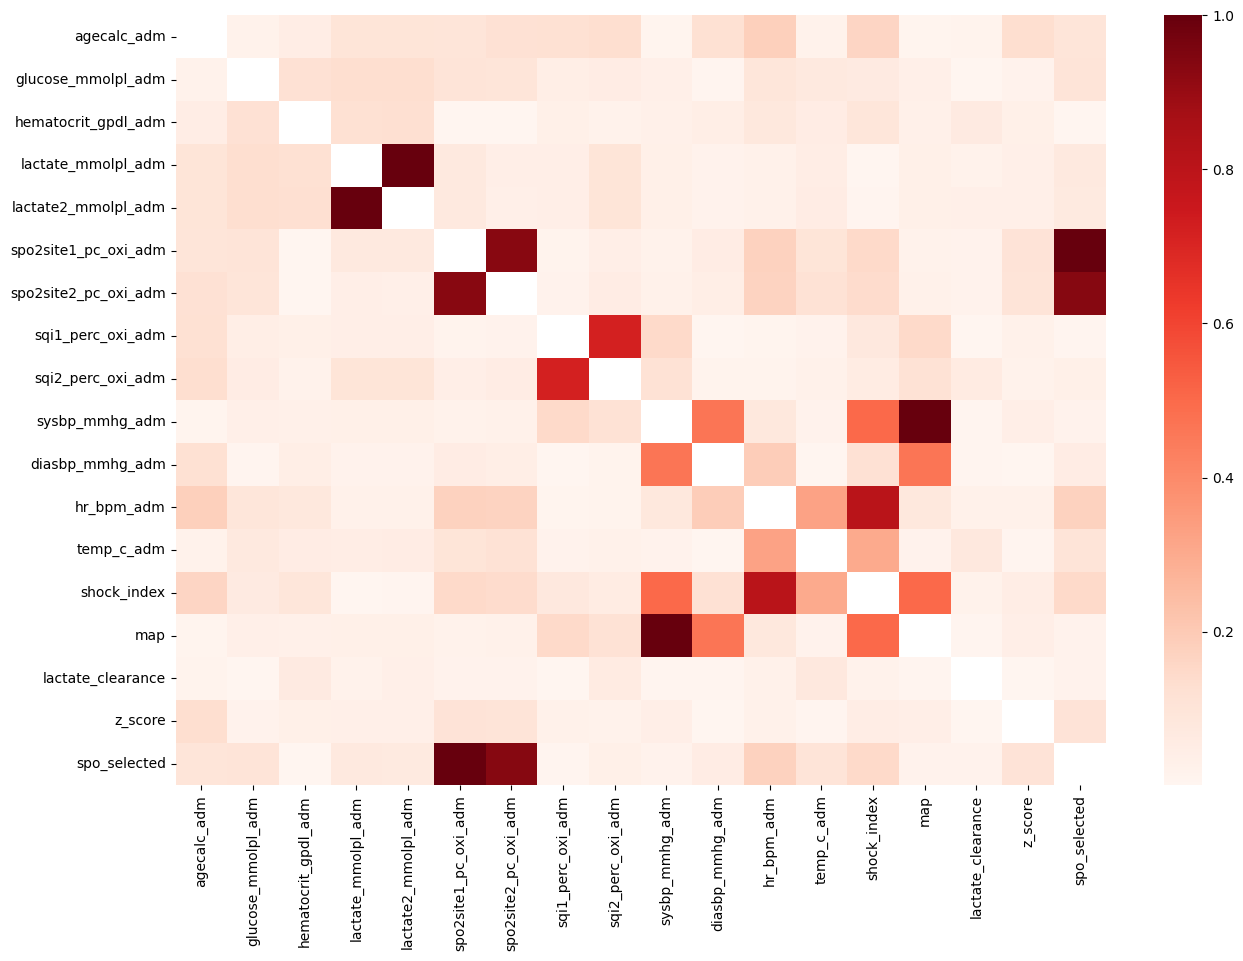

In [ ]:
heatmap_numerical(X)

In [ ]:
display(corr_matrix)

,agecalc_adm,sex_adm,caprefill_adm,glucose_mmolpl_adm,hematocrit_gpdl_adm,lactate_mmolpl_adm,lactate2_mmolpl_adm,spo2site1_pc_oxi_adm,spo2site2_pc_oxi_adm,sqi1_perc_oxi_adm,...,bcs_flag,z_score,glycemia_flag,anemia_flag,severe_anemia_flag,hyperlactatemia_flag,lactic_acidosis_flag,hypo_hyper_thermia_flag,spo_selected,hypoxemia_flag
agecalc_adm,NaN,-0.066878,0.073895,-0.020873,-0.048164,0.100524,0.099385,0.096835,0.117721,0.122539,...,0.0,0.130298,-0.012272,0.082377,0.101726,-0.095757,0.095465,0.003762,0.095590,-0.065471
sex_adm,-0.066878,NaN,0.023089,-0.027566,-0.007602,-0.070347,-0.070409,0.041668,0.019585,0.028456,...,NaN,0.057854,0.000000,0.000000,0.000000,0.029972,0.058330,0.028047,0.040861,0.075364
caprefill_adm,0.073895,0.023089,NaN,0.061818,-0.400473,0.099460,0.102184,0.021078,0.039292,0.041816,...,NaN,-0.052459,0.029936,0.426394,0.413415,0.089661,0.058359,0.000000,0.022387,0.036378
glucose_mmolpl_adm,-0.020873,-0.027566,0.061818,NaN,-0.120377,0.131553,0.131216,-0.103551,-0.097653,-0.046356,...,0.0,-0.018328,0.003016,0.123073,0.080336,-0.042913,0.096910,-0.061032,-0.105164,0.093261
hematocrit_gpdl_adm,-0.048164,-0.007602,-0.400473,-0.120377,NaN,-0.123333,-0.126825,0.002809,-0.000452,-0.034951,...,0.0,0.032414,-0.006352,-0.784099,-0.658905,0.143050,-0.079968,0.006681,-0.000232,-0.017321
lactate_mmolpl_adm,0.100524,-0.070347,0.099460,0.131553,-0.123333,NaN,0.998115,-0.073411,-0.039968,-0.042821,...,0.0,-0.036478,0.040835,0.132499,0.095485,-0.582705,0.784349,-0.047179,-0.071601,0.024622
lactate2_mmolpl_adm,0.099385,-0.070409,0.102184,0.131216,-0.126825,0.998115,NaN,-0.072323,-0.038922,-0.042578,...,0.0,-0.036198,0.042812,0.133558,0.098366,-0.581536,0.783017,-0.050291,-0.070503,0.023415
spo2site1_pc_oxi_adm,0.096835,0.041668,0.021078,-0.103551,0.002809,-0.073411,-0.072323,NaN,0.932881,0.013941,...,0.0,0.107452,0.018482,-0.000980,-0.019049,0.065715,-0.043485,0.057120,0.997346,-0.727381
spo2site2_pc_oxi_adm,0.117721,0.019585,0.039292,-0.097653,-0.000452,-0.039968,-0.038922,0.932881,NaN,0.018719,...,0.0,0.104282,0.023420,-0.006088,-0.021805,0.045245,-0.020233,0.068774,0.935913,-0.683367
sqi1_perc_oxi_adm,0.122539,0.028456,0.041816,-0.046356,-0.034951,-0.042821,-0.042578,0.013941,0.018719,NaN,...,0.0,0.025988,0.007711,0.057355,0.030879,-0.033991,-0.034055,-0.001271,0.007270,0.017445


In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

def train_model(data, 
                target, 
                categorical_cols=categorical_cols, 
                numerical_cols=numerical_cols):
    # Separate features and target
    X = data.drop(columns=[target])
    y = data[target]
    categorical_cols = [col for col in categorical_cols if col in data.columns]
    numerical_cols = [col for col in numerical_cols if col in data.columns]

    # Define preprocessing for numerical and categorical columns
    numerical_transformer = StandardScaler()  # Scale numerical columns
    categorical_transformer = OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore')  # Encode categorical columns (binary)

    # Combine preprocessing steps
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', numerical_transformer, numerical_cols),  # Apply to numerical columns
            ('cat', categorical_transformer, categorical_cols)  # Apply to categorical columns
        ]
    )

    kf = KFold(n_splits=5, shuffle=True, random_state=42)  # 5-fold CV

    # Initialize lists to store metrics from each fold
    precision_list = []
    recall_list = []
    f1_list = []
    support_list = []  # Store support from each fold
    class_1_precision_list = []
    class_1_recall_list = []
    class_1_f1_list = []

    # Store feature importances (averaged across folds)
    feature_importance_list = []

    for _, (train_idx, val_idx) in enumerate(kf.split(X)): 

        # Train-test split within this fold
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        # Preprocess the data (scale numerical and encode categorical)
        X_train_preprocessed = preprocessor.fit_transform(X_train)
        X_val_preprocessed = preprocessor.transform(X_val)

        # Train the logistic regression model
        model = LogisticRegression(class_weight='balanced', solver='liblinear')
        model.fit(X_train_preprocessed, y_train)

        # Predictions
        y_pred = model.predict(X_val_preprocessed)

        # Get classification report metrics (you can extract precision, recall, f1-score, etc.)
        report = classification_report(y_val, y_pred, output_dict=True)

        # Store metrics for averaging
        precision_list.append(report['weighted avg']['precision'])
        recall_list.append(report['weighted avg']['recall'])
        f1_list.append(report['weighted avg']['f1-score'])
        support_list.append(report['weighted avg']['support'])

        # Store Class 1's specific metrics
        class_1_precision_list.append(report['1']['precision'])
        class_1_recall_list.append(report['1']['recall'])
        class_1_f1_list.append(report['1']['f1-score'])

        # Store feature importance
        feature_importance_list.append(model.coef_[0])

    # Calculate average metrics across all folds
    avg_precision = np.mean(precision_list)
    avg_recall = np.mean(recall_list)
    avg_f1 = np.mean(f1_list)

    avg_class_1_precision = np.mean(class_1_precision_list)
    avg_class_1_recall = np.mean(class_1_recall_list)
    avg_class_1_f1 = np.mean(class_1_f1_list)

    # Print average classification report
    print(f"Average Precision (weighted): {avg_precision:.4f}")
    print(f"Average Recall (weighted): {avg_recall:.4f}")
    print(f"Average F1-Score (weighted): {avg_f1:.4f}")

    print(f"\nAverage Class 1 Precision: {avg_class_1_precision:.4f}")
    print(f"Average Class 1 Recall: {avg_class_1_recall:.4f}")
    print(f"Average Class 1 F1-Score: {avg_class_1_f1:.4f}")

    # Compute average feature importance
    avg_feature_importance = np.mean(feature_importance_list, axis=0)

    # Get feature names after preprocessing
    numerical_feature_names = numerical_cols  # Numerical feature names remain the same
    categorical_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
    feature_names = np.concatenate([numerical_feature_names, categorical_feature_names])

    # Convert to DataFrame
    feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': avg_feature_importance})
    feature_importance_df = feature_importance_df.sort_values(by='Coefficient', ascending=False)

    return feature_importance_df

In [ ]:
train_model(df, target)

Average Precision (weighted): 0.9361
Average Recall (weighted): 0.7591
Average F1-Score (weighted): 0.8306

Average Class 1 Precision: 0.0778
Average Class 1 Recall: 0.4785
Average Class 1 F1-Score: 0.1311


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [ ]:
golden_features = [
    # "lactate2_mmolpl_adm", 
                   "z_score", 
                  #  "hypo_hyper_thermia_flag", 
                #    "glycemia_flag", "hypotension_flag", 
                "glucose_mmolpl_adm", 
                #    "anemia_flag", "map", "z_score",
                  #  "hypoxemia_flag", 
                  #  "shock_index", 
                   "lactate_clearance"]
df_t = df[golden_features]
df_t[target]=df[target]
train_model(df_t, target)


Average Precision (weighted): 0.9322
Average Recall (weighted): 0.6676
Average F1-Score (weighted): 0.7678

Average Class 1 Precision: 0.0601
Average Class 1 Recall: 0.5020
Average Class 1 F1-Score: 0.1070


NotFittedError: This OneHotEncoder instance is not fitted yet. Call 'fit' with appropriate arguments before using this estimator.

In [10]:
dictionary.Category.value_counts()

Category
Categorical\n(Clinical)           69
Categorical\n(Social)             25
Categorical \n(Clinical)          17
Continuous\n(Clinical)            10
Continuous\n(Social)               5
Continuous\n(Laboratory)           4
Categorical\n(Laboratory)          3
Continuous\n(Recording data)       2
Categorical\n(Patient details)     1
Continuous \n(Clinical)            1
Continuous \n(Patient details)     1
Discrete\n(Clinical)               1
Discrete\n(Patient details)        1
Variable Type                      1
Name: count, dtype: int64